# Step 2 — Imbalance strategies across 5 validation folds (ResNet50)

Step 1 compared one run per method (validation fold 0). A single run can be lucky or unlucky, so in
step 2 every method was trained **5 times, once with each validation fold (0–4)**: 4 methods × 5 folds = 20 runs.

| | fold 0 | folds 1–4 |
|---|---|---|
| run folders | `r50_<method>` | `r50_<method>_f<fold>` |

All 20 runs use the same settings and are scored on the **same fixed test set** (3,078 images).
Only the validation fold changes: it decides the best epoch and early stopping, and the other 4 folds are
used for training.

**What this notebook answers:** is a method better than the baseline *consistently across training runs*,
or only in one run?

Sections:
1. Setup
2. Load the test labels
3. Load the 20 runs and check them against their saved metrics
4. Per-fold results
5. Mean ± std over the 5 folds → `cv_summary.csv / .tex`
6. Chart: per-fold scores → `cv_per_fold.png / .pdf`
7. Paired comparison with the baseline (per-fold differences, sign count, paired t-test) → `cv_paired_tests.csv`, `cv_paired_diff.png / .pdf`
8. Per-class F1 (mean ± std) → `cv_per_class_f1.png / .pdf`
9. Summary

All outputs go to `reports/figures/cross_validation/`.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support)

# Project root = the folder that contains Deep_Learning/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Deep_Learning").is_dir())
sys.path.insert(0, str(ROOT))
from Deep_Learning.config import RUNS_DIR, SPLITS_CSV, short_class_names

CLASSES = short_class_names()             # ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']
K = len(CLASSES)
OUT = ROOT / "reports" / "figures" / "cross_validation"
OUT.mkdir(parents=True, exist_ok=True)

BASELINE = "none"
METHODS = ["none", "sampler", "weights", "oversample"]          # fixed order everywhere
OTHERS = [m for m in METHODS if m != BASELINE]
LABEL = {"none": "None (baseline)", "sampler": "Weighted sampler",
         "weights": "Class-weighted loss", "oversample": "Oversampling"}
# Same colour per method as in the step 1 notebook
COLOR = {"none": "#2a78d6", "sampler": "#eb6834", "weights": "#1baf7a", "oversample": "#eda100"}
METRICS = ["acc", "balanced_acc", "macro_f1"]
NAMES = {"acc": "Accuracy", "balanced_acc": "Balanced accuracy", "macro_f1": "Macro-F1"}

SURFACE, INK, INK_2, GRID = "#ffffff", "#0b0b0b", "#52514e", "#e4e3df"
HALO = dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
pd.set_option("display.precision", 4)

def save(fig, stem):
    fig.savefig(OUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")

def pp(x):
    # signed percentage points, without "-0.0"
    v = round(100 * x, 1)
    return f"{v + 0.0:+.1f}"

def clean(ax, grid="x"):
    getattr(ax, f"{grid}axis").grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

print("project root:", ROOT)
print("outputs     :", OUT)

project root: /home2/luudh/luudh/MyFile/comp_vision/computer_vision_project
outputs     : /home2/luudh/luudh/MyFile/comp_vision/computer_vision_project/reports/figures/cross_validation


## 2. Load the test labels

Same as step 1: the test rows of `splits.csv`, in the order the (unshuffled) test loader used.

In [2]:
splits = pd.read_csv(SPLITS_CSV)
test = splits[splits.split == "test"].reset_index(drop=True)
y_true = test.label.to_numpy()
print(len(y_true), "test images;", dict(zip(CLASSES, np.bincount(y_true, minlength=K).tolist())))

3078 test images; {'CBB': 149, 'CBSD': 306, 'CGM': 345, 'CMD': 1880, 'Healthy': 398}


## 3. Load the 20 runs and check them

Each run is identified by `imbalance` and `val_fold` from its `config.json` (not by its folder name).
Metrics recomputed from `test_probs.npy` must match the run's saved `test_metrics.json`.

In [3]:
def metric_row(p):
    _, rec, f1, _ = precision_recall_fscore_support(y_true, p, labels=range(K), zero_division=0)
    row = {"acc": accuracy_score(y_true, p),
           "balanced_acc": balanced_accuracy_score(y_true, p),
           "macro_f1": f1_score(y_true, p, average="macro")}
    row.update({f"F1 {c}": v for c, v in zip(CLASSES, f1)})
    row.update({f"recall {c}": v for c, v in zip(CLASSES, rec)})
    return row

rows = []
for run_dir in sorted(RUNS_DIR.glob("r50_*")):
    if not (run_dir / "test_metrics.json").exists():
        print("skip (not finished):", run_dir.name)
        continue
    cfg = json.loads((run_dir / "config.json").read_text())
    # only full-data grouped-split ResNet50 runs (step 3 adds random-split and learning-curve runs)
    if (cfg["model"] != "resnet50" or cfg.get("split", "grouped") != "grouped"
            or cfg.get("train_frac", 1.0) != 1.0):
        continue
    saved = json.loads((run_dir / "test_metrics.json").read_text())
    probs = np.load(run_dir / "test_probs.npy")
    assert probs.shape == (len(y_true), K), f"{run_dir.name}: unexpected shape {probs.shape}"
    row = {"method": cfg["imbalance"], "fold": cfg["val_fold"], "run": run_dir.name,
           "best_epoch": saved["best_epoch"], "val_macro_f1": saved["val_macro_f1"],
           **metric_row(probs.argmax(1))}
    for k in METRICS:
        assert np.isclose(row[k], saved[f"test_{k}"], atol=1e-6), f"{run_dir.name}: {k} does not match"
    rows.append(row)

cv = pd.DataFrame(rows)
assert not cv.duplicated(["method", "fold"]).any(), "two runs for the same (method, fold)"
cv["method"] = pd.Categorical(cv.method, METHODS, ordered=True)
cv = cv.sort_values(["method", "fold"]).reset_index(drop=True)
FOLDS = sorted(int(f) for f in cv.fold.unique())

# Which (method, fold) runs exist? Every cell should show the run folder.
grid = cv.pivot(index="method", columns="fold", values="run")
assert grid.notna().all().all(), "some (method, fold) runs are missing"
print(f"{len(cv)} runs verified, folds {FOLDS}")
grid

20 runs verified, folds [0, 1, 2, 3, 4]


fold,0,1,2,3,4
method,,,,,
none,r50_none,r50_none_f1,r50_none_f2,r50_none_f3,r50_none_f4
sampler,r50_sampler,r50_sampler_f1,r50_sampler_f2,r50_sampler_f3,r50_sampler_f4
weights,r50_weights,r50_weights_f1,r50_weights_f2,r50_weights_f3,r50_weights_f4
oversample,r50_oversample,r50_oversample_f1,r50_oversample_f2,r50_oversample_f3,r50_oversample_f4


## 4. Per-fold results

One row per method, one column per fold. Read across a row to see how much a method varies between
training runs; read down a column to compare methods trained on the same split.

In [4]:
per_fold = {k: cv.pivot(index="method", columns="fold", values=k) for k in ["macro_f1", "balanced_acc", "acc"]}
pd.concat(per_fold, names=["metric"]).mul(100).round(2)

fold                         0      1      2      3      4
metric       method                                       
macro_f1     none        77.54  78.47  78.06  76.68  77.53
             sampler     76.38  77.47  76.10  76.73  78.28
             weights     78.54  78.46  78.55  77.70  78.26
             oversample  78.03  79.31  77.10  77.55  76.70
balanced_acc none        77.48  77.63  78.68  76.07  77.00
             sampler     77.63  78.38  76.79  76.51  79.86
             weights     79.82  79.48  79.83  78.24  79.18
             oversample  78.68  78.71  76.22  77.55  76.97
acc          none        87.75  88.17  87.78  87.33  87.85
             sampler     86.45  87.36  86.65  87.59  87.49
             weights     87.62  87.72  88.01  87.72  87.75
             oversample  88.04  88.53  87.46  87.52  87.17

In [5]:
# Best epoch and validation macro-F1 of every run (training behaviour)
cv.pivot(index="method", columns="fold", values=["best_epoch", "val_macro_f1"]).round(4)

best_epoch                         val_macro_f1                  \
fold                0     1     2     3     4            0       1       2   
method                                                                       
none             10.0  13.0   9.0   5.0  11.0       0.7923  0.7945  0.8151   
sampler          12.0   7.0   8.0   8.0  10.0       0.7894  0.7739  0.7906   
weights           6.0  14.0  10.0  11.0  11.0       0.7876  0.7881  0.8032   
oversample       12.0  11.0   7.0   5.0   5.0       0.7958  0.7885  0.7911   

                            
fold             3       4  
method                      
none        0.7985  0.7985  
sampler     0.7989  0.7793  
weights     0.8050  0.7949  
oversample  0.8003  0.7912

## 5. Mean ± std over the 5 folds

`std` is the sample standard deviation over the 5 runs: it measures how much a method's test score
moves when it is retrained. It does **not** include test-set sampling noise (the test set is the same
for all runs); step 1's bootstrap covers that.

In [6]:
score_cols = METRICS + [f"F1 {c}" for c in CLASSES] + [f"recall {c}" for c in CLASSES]
summary = cv.groupby("method", observed=True)[score_cols].agg(["mean", "std"])
summary.to_csv(OUT / "cv_summary.csv", float_format="%.4f")

# Display as "mean ± std" in %
fmt = pd.DataFrame({c: [f"{100*summary.loc[m, (c, 'mean')]:.1f} ± {100*summary.loc[m, (c, 'std')]:.1f}"
                        for m in METHODS] for c in score_cols}, index=METHODS)
fmt

,acc,balanced_acc,macro_f1,F1 CBB,F1 CBSD,F1 CGM,F1 CMD,F1 Healthy,recall CBB,recall CBSD,recall CGM,recall CMD,recall Healthy
none,87.8 ± 0.3,77.4 ± 1.0,77.7 ± 0.7,60.5 ± 2.5,78.8 ± 1.2,78.1 ± 0.8,95.8 ± 0.2,75.1 ± 0.6,61.5 ± 3.2,77.5 ± 1.7,76.9 ± 2.2,96.3 ± 0.7,74.8 ± 1.0
sampler,87.1 ± 0.5,77.8 ± 1.3,77.0 ± 0.9,60.1 ± 2.0,77.7 ± 2.6,78.1 ± 0.6,95.6 ± 0.3,73.5 ± 1.3,64.4 ± 4.9,77.5 ± 6.5,77.0 ± 1.0,94.8 ± 1.1,75.4 ± 2.4
weights,87.8 ± 0.1,79.3 ± 0.7,78.3 ± 0.4,61.9 ± 1.8,80.4 ± 1.1,78.4 ± 0.8,95.7 ± 0.2,75.1 ± 0.9,65.4 ± 5.0,80.8 ± 1.4,79.2 ± 1.6,94.6 ± 0.5,76.5 ± 3.1
oversample,87.7 ± 0.5,77.6 ± 1.1,77.7 ± 1.0,61.1 ± 2.3,78.5 ± 1.6,78.4 ± 1.4,95.8 ± 0.3,74.9 ± 0.9,63.1 ± 5.3,76.9 ± 3.4,76.1 ± 2.9,96.1 ± 0.5,76.0 ± 2.1


In [7]:
# LaTeX table: mean ± std (%), best mean per column in bold
cols = METRICS + [f"F1 {c}" for c in CLASSES]
heads = ["Acc.", "Bal. acc.", "Macro-F1"] + CLASSES
# compare at the shown precision so ties (e.g. 87.8 vs 87.8) are all bold
best = {c: (100 * summary[(c, "mean")]).round(1).max() for c in cols}
lines = [
    r"\begin{table}[t]", r"\centering", r"\small",
    r"\caption{Test-set results (\%, mean $\pm$ std over 5 runs, one per validation fold) of ResNet50 "
    r"under each class-imbalance strategy. The last five columns are per-class F1. "
    r"Best mean per column in bold.}",
    r"\label{tab:imbalance-cv}",
    r"\begin{tabular}{l" + "c" * len(cols) + "}", r"\toprule",
    r" & \multicolumn{3}{c}{Overall} & \multicolumn{" + str(K) + r"}{c}{Per-class F1} \\",
    r"\cmidrule(lr){2-4}\cmidrule(lr){5-" + str(4 + K) + "}",
    "Method & " + " & ".join(heads) + r" \\", r"\midrule",
]
for m in METHODS:
    cells = []
    for c in cols:
        mu, sd = 100 * summary.loc[m, (c, "mean")], 100 * summary.loc[m, (c, "std")]
        s = f"{mu:.1f}"
        s = rf"\textbf{{{s}}}" if round(mu, 1) == best[c] else s
        cells.append(rf"{s}$\pm${sd:.1f}")
    lines.append(LABEL[m] + " & " + " & ".join(cells) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
tex = "\n".join(lines) + "\n"
(OUT / "cv_summary.tex").write_text(tex)
print(tex)

\begin{table}[t]
\centering
\small
\caption{Test-set results (\%, mean $\pm$ std over 5 runs, one per validation fold) of ResNet50 under each class-imbalance strategy. The last five columns are per-class F1. Best mean per column in bold.}
\label{tab:imbalance-cv}
\begin{tabular}{lcccccccc}
\toprule
 & \multicolumn{3}{c}{Overall} & \multicolumn{5}{c}{Per-class F1} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-9}
Method & Acc. & Bal. acc. & Macro-F1 & CBB & CBSD & CGM & CMD & Healthy \\
\midrule
None (baseline) & \textbf{87.8}$\pm$0.3 & 77.4$\pm$1.0 & 77.7$\pm$0.7 & 60.5$\pm$2.5 & 78.8$\pm$1.2 & 78.1$\pm$0.8 & \textbf{95.8}$\pm$0.2 & \textbf{75.1}$\pm$0.6 \\
Weighted sampler & 87.1$\pm$0.5 & 77.8$\pm$1.3 & 77.0$\pm$0.9 & 60.1$\pm$2.0 & 77.7$\pm$2.6 & 78.1$\pm$0.6 & 95.6$\pm$0.3 & 73.5$\pm$1.3 \\
Class-weighted loss & \textbf{87.8}$\pm$0.1 & \textbf{79.3}$\pm$0.7 & \textbf{78.3}$\pm$0.4 & \textbf{61.9}$\pm$1.8 & \textbf{80.4}$\pm$1.1 & \textbf{78.4}$\pm$0.8 & 95.7$\pm$0.2 & \textbf{75.1}$\pm$0.9 \

## 6. Chart: per-fold scores

Each small dot is one run (one fold); the large dot is the mean over the 5 folds, and the bar is ± 1 std.
Overlapping spreads mean the methods are hard to tell apart from run to run.

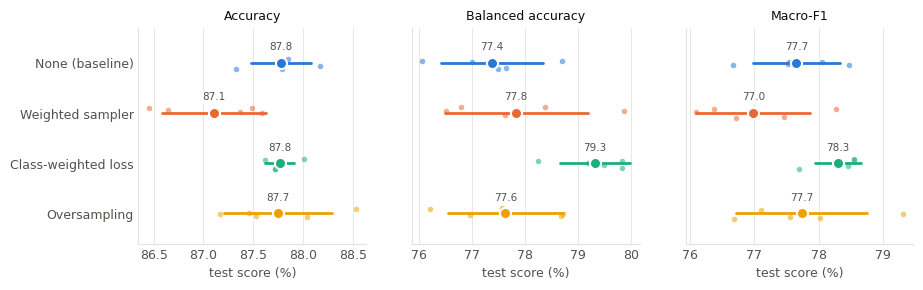

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
y = np.arange(len(METHODS))[::-1]
rng = np.random.default_rng(0)
for ax, k in zip(axes, METRICS):
    for yi, m in zip(y, METHODS):
        v = 100 * per_fold[k].loc[m].to_numpy()
        ax.plot(v, yi + rng.uniform(-0.12, 0.12, len(v)), "o", ms=4, color=COLOR[m], alpha=0.55, mew=0)
        mu, sd = v.mean(), v.std(ddof=1)
        ax.plot([mu - sd, mu + sd], [yi, yi], color=COLOR[m], lw=2, solid_capstyle="round")
        ax.plot(mu, yi, "o", ms=8, color=COLOR[m], mec=SURFACE, mew=1.5, zorder=3)
        ax.annotate(f"{mu:.1f}", (mu, yi), xytext=(0, 8), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7.5, color=INK_2, bbox=HALO, zorder=4)
    ax.set_title(NAMES[k], fontsize=9)
    ax.set_xlabel("test score (%)")
    clean(ax)
axes[0].set_yticks(y, [LABEL[m] for m in METHODS])
axes[0].set_ylim(-0.6, len(METHODS) - 0.3)
save(fig, "cv_per_fold")
plt.show()

## 7. Paired comparison with the baseline

Because every method was trained on the same 5 splits, we compare **fold by fold**:
for each fold, *difference = method − baseline* on the same split. Then for each method and metric:

- **mean diff** and its **95% CI** (t-distribution, 4 degrees of freedom);
- **folds better**: in how many of the 5 folds the method beat the baseline (5/5 or 0/5 = fully consistent);
- **paired t-test** p-value, and Holm-corrected for the 3 methods compared with the baseline.

We do not use the Wilcoxon signed-rank test: with only 5 pairs its smallest possible two-sided p-value is
2/32 = 0.0625, so it can never reach p < 0.05. With 5 folds the t-test has little power too, so
read the sign count and the CI together with the p-value.

In [9]:
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty_like(p); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

rows = []
for k in METRICS:
    t_crit = stats.t.ppf(0.975, df=len(FOLDS) - 1)
    for m in OTHERS:
        d = (per_fold[k].loc[m] - per_fold[k].loc[BASELINE]).to_numpy()
        se = d.std(ddof=1) / np.sqrt(len(d))
        rows.append({"metric": k, "method": m, "mean_diff": d.mean(), "std_diff": d.std(ddof=1),
                     "ci_low": d.mean() - t_crit * se, "ci_high": d.mean() + t_crit * se,
                     "folds_better": f"{(d > 0).sum()}/{len(d)}",
                     "p_ttest": stats.ttest_rel(per_fold[k].loc[m], per_fold[k].loc[BASELINE]).pvalue,
                     **{f"diff_fold{f}": v for f, v in zip(FOLDS, d)}})
paired = pd.DataFrame(rows)
paired["p_holm"] = paired.groupby("metric").p_ttest.transform(holm)
paired["significant (p_holm < 0.05)"] = paired.p_holm < 0.05
paired.to_csv(OUT / "cv_paired_tests.csv", index=False, float_format="%.4g")

show = paired[["metric", "method", "mean_diff", "ci_low", "ci_high", "folds_better", "p_ttest", "p_holm",
               "significant (p_holm < 0.05)"]].copy()
show[["mean_diff", "ci_low", "ci_high"]] *= 100          # percentage points
show.set_index(["metric", "method"]).round(3)

mean_diff  ci_low  ci_high folds_better  p_ttest  \
metric       method                                                         
acc          sampler        -0.669  -1.454    0.115          1/5    0.077   
             weights        -0.013  -0.423    0.397          2/5    0.934   
             oversample     -0.032  -0.594    0.529          3/5    0.880   
balanced_acc sampler         0.458  -1.644    2.559          4/5    0.578   
             weights         1.938   1.343    2.532          5/5    0.001   
             oversample      0.253  -1.767    2.273          3/5    0.746   
macro_f1     sampler        -0.664  -1.989    0.661          2/5    0.236   
             weights         0.646   0.115    1.178          4/5    0.028   
             oversample      0.083  -1.042    1.207          3/5    0.848   

                         p_holm  significant (p_holm < 0.05)  
metric       method                                           
acc          sampler      0.231                        False  
             weights      1.000                        False  
             oversample   1.000                        False  
balanced_acc sampler      1.000                        False  
             weights      0.002                         True  
             oversample   1.000                        False  
macro_f1     sampler      0.473                        False  
             weights      0.084                        False  
             oversample   0.848                        False

The same comparison as a chart. Each small dot is the difference on one fold, the large dot the mean,
and the bar the 95% CI of the mean. Points right of the dashed line = better than the baseline on that fold.

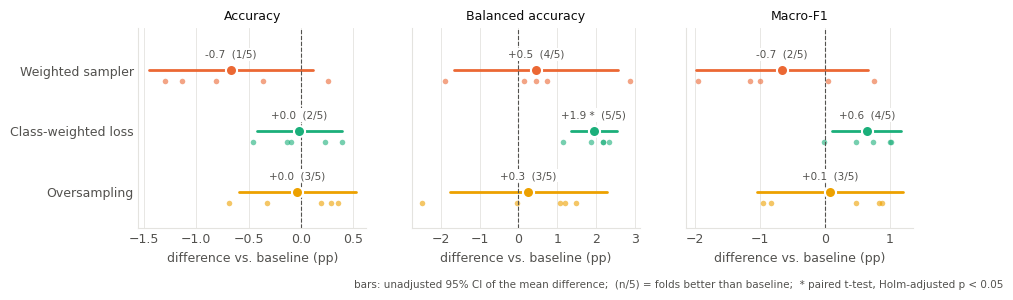

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
y = np.arange(len(OTHERS))[::-1]
for ax, k in zip(axes, METRICS):
    for yi, m in zip(y, OTHERS):
        r = paired[(paired.metric == k) & (paired.method == m)].iloc[0]
        d = 100 * np.array([r[f"diff_fold{f}"] for f in FOLDS])
        ax.plot(d, np.full(len(d), yi - 0.18), "o", ms=4, color=COLOR[m], alpha=0.6, mew=0)
        ax.plot([100 * r.ci_low, 100 * r.ci_high], [yi, yi], color=COLOR[m], lw=2, solid_capstyle="round")
        ax.plot(100 * r.mean_diff, yi, "o", ms=8, color=COLOR[m], mec=SURFACE, mew=1.5, zorder=3)
        star = " *" if r["significant (p_holm < 0.05)"] else ""
        ax.annotate(f"{pp(r.mean_diff)}{star}  ({r.folds_better})", (100 * r.mean_diff, yi),
                    xytext=(0, 8), textcoords="offset points", ha="center", va="bottom",
                    fontsize=7.5, color=INK_2, bbox=HALO, zorder=4)
    ax.axvline(0, color=INK_2, lw=0.8, ls="--")
    ax.set_title(NAMES[k], fontsize=9)
    ax.set_xlabel("difference vs. baseline (pp)")
    clean(ax)
axes[0].set_yticks(y, [LABEL[m] for m in OTHERS])
axes[0].set_ylim(-0.6, len(OTHERS) - 0.3)
fig.text(0.99, -0.12, "bars: unadjusted 95% CI of the mean difference;  (n/5) = folds better than baseline;  * paired t-test, Holm-adjusted p < 0.05",
         ha="right", fontsize=7.5, color=INK_2)
save(fig, "cv_paired_diff")
plt.show()

## 8. Per-class F1 (mean ± std over 5 folds)

Which classes does each method help? Dots are means, bars ± 1 std.

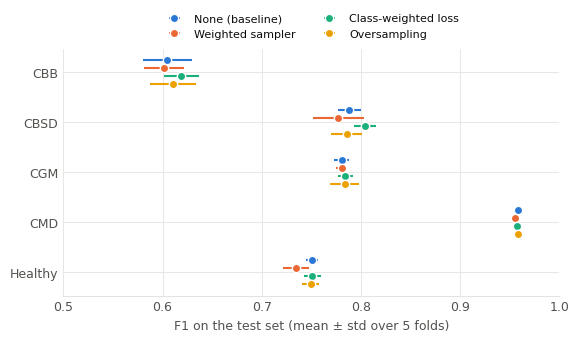

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
offsets = np.linspace(0.24, -0.24, len(METHODS))
y = np.arange(K)[::-1]
for yi in y:
    ax.axhline(yi, color=GRID, lw=0.6, zorder=0)
for off, m in zip(offsets, METHODS):
    mu = np.array([summary.loc[m, (f"F1 {c}", "mean")] for c in CLASSES])
    sd = np.array([summary.loc[m, (f"F1 {c}", "std")] for c in CLASSES])
    ax.errorbar(mu, y + off, xerr=sd, fmt="o", ms=6, color=COLOR[m], mec=SURFACE, mew=1.0,
                elinewidth=1.5, capsize=0, label=LABEL[m], zorder=3)
ax.set_yticks(y, CLASSES)
ax.set_xlabel("F1 on the test set (mean ± std over 5 folds)")
ax.set_xlim(0.5, 1.0)
clean(ax)
ax.spines["left"].set_visible(False)
ax.legend(ncol=2, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
save(fig, "cv_per_class_f1")
plt.show()

In [12]:
# Per-class differences vs. baseline: mean over folds (pp) and folds better
rows = []
for m in OTHERS:
    for c in CLASSES:
        for kind in ["F1", "recall"]:
            col = f"{kind} {c}"
            d = (cv[cv.method == m].set_index("fold")[col] - cv[cv.method == BASELINE].set_index("fold")[col])
            rows.append({"method": m, "class": c, "metric": kind,
                         "value": f"{pp(d.mean())} ({(d > 0).sum()}/{len(d)})"})
pd.DataFrame(rows).pivot(index=["metric", "class"], columns="method", values="value")[OTHERS]

method             sampler     weights  oversample
metric class                                      
F1     CBB      -0.4 (1/5)  +1.4 (3/5)  +0.6 (3/5)
       CBSD     -1.1 (2/5)  +1.6 (4/5)  -0.3 (3/5)
       CGM      +0.0 (3/5)  +0.4 (3/5)  +0.3 (4/5)
       CMD      -0.2 (1/5)  -0.1 (2/5)  +0.0 (3/5)
       Healthy  -1.6 (0/5)  +0.0 (2/5)  -0.2 (2/5)
recall CBB      +3.0 (4/5)  +3.9 (4/5)  +1.6 (3/5)
       CBSD     +0.1 (4/5)  +3.4 (5/5)  -0.6 (3/5)
       CGM      +0.1 (2/5)  +2.3 (5/5)  -0.8 (3/5)
       CMD      -1.5 (1/5)  -1.7 (1/5)  -0.2 (2/5)
       Healthy  +0.7 (3/5)  +1.8 (4/5)  +1.3 (4/5)

## 9. Summary

Printed from the tables above, so it stays correct if the runs change.

In [13]:
print(f"{len(cv)} runs: {len(METHODS)} methods x {len(FOLDS)} folds, same test set ({len(y_true)} images)\n")
for k in METRICS:
    print(f"{NAMES[k]}  (mean ± std over folds)")
    for m in METHODS:
        line = f"  {LABEL[m]:<20} {100*summary.loc[m, (k, 'mean')]:5.1f} ± {100*summary.loc[m, (k, 'std')]:.1f}"
        if m != BASELINE:
            r = paired[(paired.metric == k) & (paired.method == m)].iloc[0]
            line += (f"   diff {pp(r.mean_diff)} pp [{pp(r.ci_low)}, {pp(r.ci_high)}], "
                     f"better on {r.folds_better} folds, p_holm={r.p_holm:.3g}"
                     + ("  SIGNIFICANT" if r["significant (p_holm < 0.05)"] else ""))
        print(line)
    print()
print("Files written to", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

20 runs: 4 methods x 5 folds, same test set (3078 images)

Accuracy  (mean ± std over folds)
  None (baseline)       87.8 ± 0.3
  Weighted sampler      87.1 ± 0.5   diff -0.7 pp [-1.5, +0.1], better on 1/5 folds, p_holm=0.231
  Class-weighted loss   87.8 ± 0.1   diff +0.0 pp [-0.4, +0.4], better on 2/5 folds, p_holm=1
  Oversampling          87.7 ± 0.5   diff +0.0 pp [-0.6, +0.5], better on 3/5 folds, p_holm=1

Balanced accuracy  (mean ± std over folds)
  None (baseline)       77.4 ± 1.0
  Weighted sampler      77.8 ± 1.3   diff +0.5 pp [-1.6, +2.6], better on 4/5 folds, p_holm=1
  Class-weighted loss   79.3 ± 0.7   diff +1.9 pp [+1.3, +2.5], better on 5/5 folds, p_holm=0.00247  SIGNIFICANT
  Oversampling          77.6 ± 1.1   diff +0.3 pp [-1.8, +2.3], better on 3/5 folds, p_holm=1

Macro-F1  (mean ± std over folds)
  None (baseline)       77.7 ± 0.7
  Weighted sampler      77.0 ± 0.9   diff -0.7 pp [-2.0, +0.7], better on 2/5 folds, p_holm=0.473
  Class-weighted loss   78.3 ± 0.4   d